In [52]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [53]:
activos = ["AAPL", "MSFT", "GOOGL", ]
precios = yf.download(activos, start="2024-01-01", end="2026-01-01", auto_adjust=True)

print("--- Calidad de los Datos ---")
print("Dimensiones:", precios.shape)
print("\nValores faltantes:\n", precios.isna().sum())

[*********************100%***********************]  3 of 3 completed

--- Calidad de los Datos ---
Dimensiones: (502, 15)

Valores faltantes:
 Price   Ticker
Close   AAPL      0
        GOOGL     0
        MSFT      0
High    AAPL      0
        GOOGL     0
        MSFT      0
Low     AAPL      0
        GOOGL     0
        MSFT      0
Open    AAPL      0
        GOOGL     0
        MSFT      0
Volume  AAPL      0
        GOOGL     0
        MSFT      0
dtype: int64


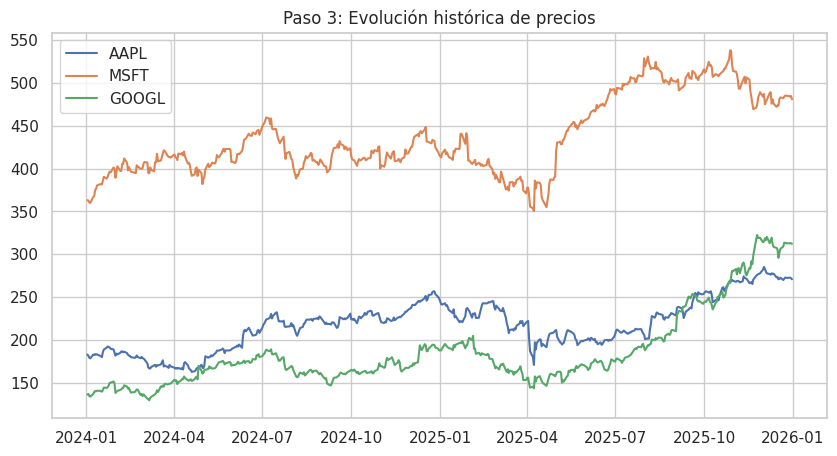

In [54]:
cierre = precios["Close"]
fig, ax = plt.subplots(figsize=(10, 5))
for activo in activos:
    ax.plot(cierre.index, cierre[activo], label=activo)
ax.set_title("Paso 3: Evolución histórica de precios")
ax.legend()
plt.show()

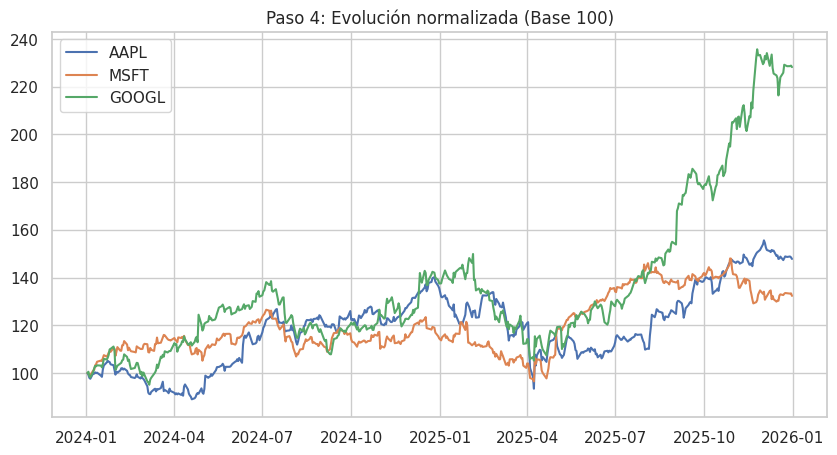

In [55]:
cierre_normalizado = cierre / cierre.iloc[0] * 100
fig, ax = plt.subplots(figsize=(10, 5))
for activo in activos:
    ax.plot(cierre_normalizado.index, cierre_normalizado[activo], label=activo)
ax.set_title("Paso 4: Evolución normalizada (Base 100)")
ax.legend()
plt.show()

In [56]:
# --- Paso 5: Rendimientos ---
rendimientos = cierre.pct_change().dropna()

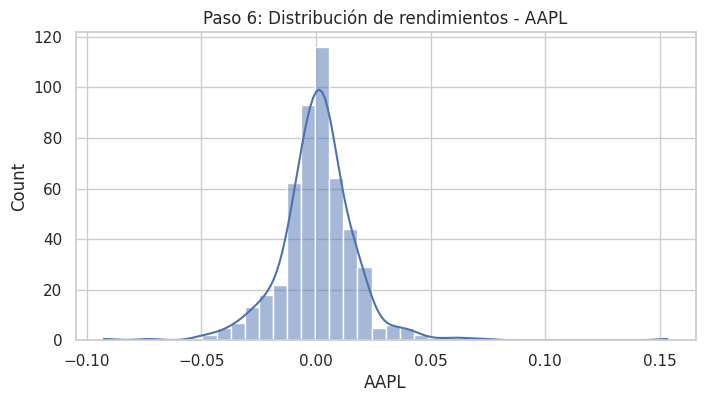

In [57]:
plt.figure(figsize=(8, 4))
sns.histplot(rendimientos["AAPL"], bins=40, kde=True)
plt.title("Paso 6: Distribución de rendimientos - AAPL")
plt.show()

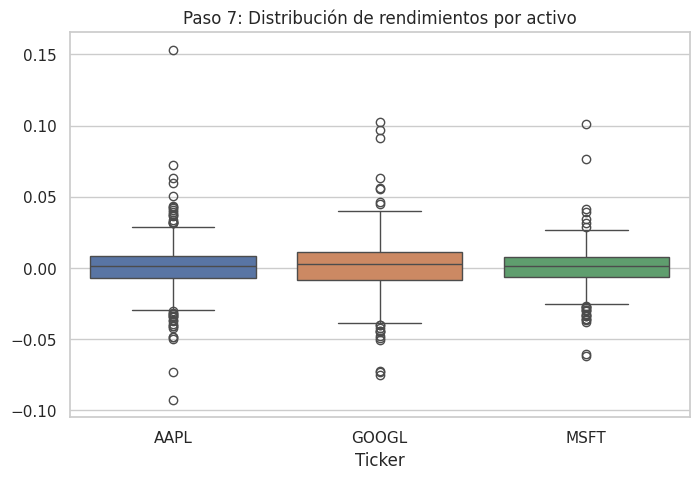

In [58]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=rendimientos)
plt.title("Paso 7: Distribución de rendimientos por activo")
plt.show()

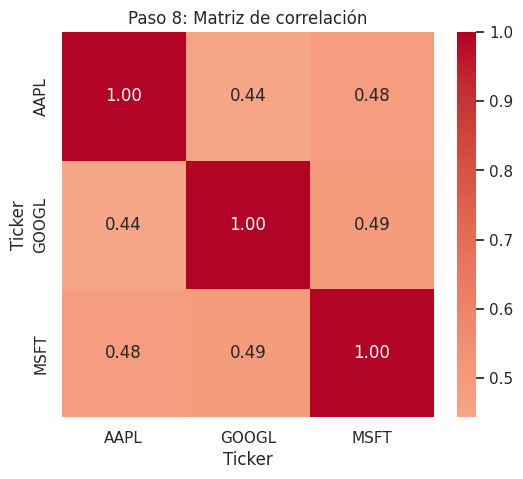

In [59]:
correlacion = rendimientos.corr()
plt.figure(figsize=(6, 5))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Paso 8: Matriz de correlación")
plt.show()

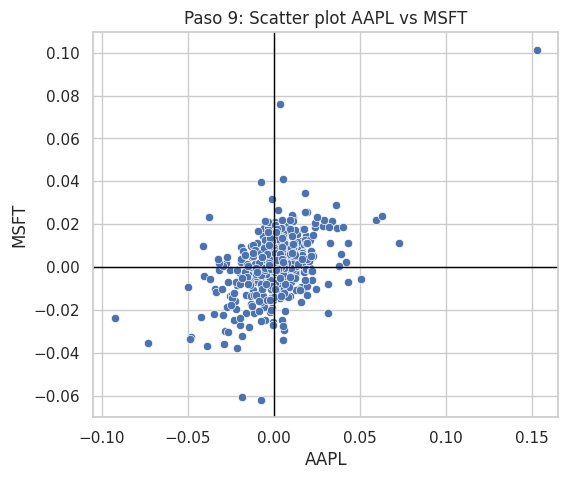

In [60]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=rendimientos, x="AAPL", y="MSFT")
plt.axhline(0, linewidth=1, color="black")
plt.axvline(0, linewidth=1, color="black")
plt.title("Paso 9: Scatter plot AAPL vs MSFT")
plt.show()

# --- Paso 10 conclusiones ---
hallazgos
1. matriz pago 8
GOOGL Y MFST tiene la correlacion mas alta (0.49) mientras que AAPL y GOOGLE la mas baja (0.44)
los rendimientos de GOOGL y MSFT tienen la mayor tendencia a moverse en la misma direccion
2. Boxplot paso 7
La caja cental y los bigotes de GOOGLson los mas amplios de los Tres
GOOGL fue el activo mas Volatil del grupo, presentando mayores fluctuaciones diarias en comparacion con APPL Y MSFT
3. grafico paso 4
La linea verde de GOOGL termina encima de las otras, superando el nivel de 220 al final del periodo
GOOGL logro el mayor crecimiento porcentual acumulado de los tre activos. y genera un rendimiento muy superior sobre la inversion inicial en comparacion con AAPL y MSFT



# --- RETO FINAL 2.2 ---
Pregunta 1
¿Cuál activo presenta mayor dispersión de rendimientos?

*   GOOGL, ya que su boxplot tiene la caja y los bigotes mas amplios

Pregunta 2
¿Cuáles dos activos presentan mayor correlación?

*  GOOGL y MSFT, con el valor mas alto de 0.49


Pregunta 3
¿Cuáles presentan menor correlación?

*  AAPL y GOOGL con el valor mas bajo de 0.44

Pregunta 4

¿Existe algún día donde varios activos tengan movimientos extremos simultáneamente?

*   Si, observando la grafica normalizada, hay momentos puntuales (como en el medio del grafico) donde las tres lineas sufre caidas pronunciadas al mismo tiempo


Pregunta 5

¿La evolución normalizada cuenta la misma historia que los precios originales?

*   No cuentan la misma historia. La gráfica normalizada muestra el porcentaje de crecimiento desde un mismo punto de partida, ignorando qué acción es más cara en dinero real

Pregunta 6

¿Qué información aporta el histograma que no aporta el gráfico temporal?

*   El histograma revela la frecuencia y distribucion estadistica de las ganancias o perdidas, sin importar en que fecha exacta ocurrieron

Pregunta 7

¿Qué información aporta el scatter plot que no aporta el heatmap?

*   El Scatter Plot deja ver el comportamiento diario exacto y descubrir valores atípicos (dias anormales), mientras que el heatmap solo da un numero de resumen general

